In [1]:
# Permite que la imagen se dibuje en el jupyter
%matplotlib inline

# Que la imagen termine con una mejor resolución
%config InlineBackend.figure_format = 'retina'

import numpy as np
import torch
from torch import nn
from torch import optim
import torch.nn.functional as F
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import kagglehub
import os
import shutil


print("Librerías importadas correctamente")

Librerías importadas correctamente


In [3]:
# Ahora definimos la transformacion
transform = transforms.Compose([
    transforms.Resize((224, 224)), # Redimencionamos la imagen para que las erntradas sean mas pocas, ni muy pequeño ni muy grande
    transforms.ToTensor(), # Valores entre 0-1, mas faciles de procesar que los valores RGB que van del 0-255
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))  # Normaliza RGB valores entre -1 y 1
]) 

print("Transformación definida")

Transformación definida


In [4]:


# Permite crear la carperta data sino existe debido a que ahi se guardar el dataset
if not os.path.exists('data'):
    os.makedirs('data')

# Descargar desde la API de Kaggle el dataset
print("Descargando dataset...")
temp_path = kagglehub.dataset_download("rm1000/grape-disease-dataset-original")

# Copiar a la carpeta del proyecto
dataset_path = 'data/grape-disease-dataset'
if os.path.exists(dataset_path):
    shutil.rmtree(dataset_path)
shutil.copytree(temp_path, dataset_path)

print(f"Dataset guardado en: {dataset_path}")

# Uso la ruta local
trainset = datasets.ImageFolder(dataset_path + '/Original Data/train/', transform=transform)
testset = datasets.ImageFolder(dataset_path + '/Original Data/test/', transform=transform)

# Crear DataLoader
trainloader = torch.utils.data.DataLoader(trainset, batch_size=64, shuffle=True)
testloader = torch.utils.data.DataLoader(testset, batch_size=64, shuffle=False)

print("Dataset cargado correctamente")

Descargando dataset...
Dataset guardado en: data/grape-disease-dataset
Dataset cargado correctamente


In [7]:
# Obtener número de clases
num_clases = len(trainset.classes)
print(f"Número de clases: {num_clases}")
print(f"Clases: {trainset.classes}")

Número de clases: 4
Clases: ['Black Rot', 'ESCA', 'Healthy', 'Leaf Blight']


In [9]:
# Ahora creamos la red neuronal
num_classes = 4

class RedUvas(nn.Module):
    def __init__(self, num_classes):
        super(RedUvas, self).__init__()
        self.fc1 = nn.Linear(150528, 256)  # 224*224*3
        self.fc2 = nn.Linear(256, 128)
        self.fc3 = nn.Linear(128, num_classes)
        self.relu = nn.ReLU()
        
    def forward(self, x):
        x = x.view(x.size(0), -1)  # Aplanar
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.fc3(x)
        return x

model = RedUvas(num_classes)
print("Modelo creado exitosamente")
print(model)

Modelo creado exitosamente
RedUvas(
  (fc1): Linear(in_features=150528, out_features=256, bias=True)
  (fc2): Linear(in_features=256, out_features=128, bias=True)
  (fc3): Linear(in_features=128, out_features=4, bias=True)
  (relu): ReLU()
)


In [10]:
# Calcular precisión antes de entrnar
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

correct = 0
total = 0

with torch.no_grad():
    for images, labels in trainloader:
        images = images.to(device)
        labels = labels.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs.data, 1)
        
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

accuracy_sin_entrenar = 100 * correct / total
print(f"Precisión sin entrenar (Grape Disease): {accuracy_sin_entrenar:.2f}%")

Precisión sin entrenar (Grape Disease): 26.49%


Tamaño del lote: torch.Size([64, 3, 224, 224])
Etiquetas: tensor([3, 3, 1, 1, 2, 2, 3, 2, 0, 2])

Salida de la red (probabilidades):
tensor([[ 0.0646,  0.0677, -0.0108, -0.0522]], grad_fn=<AddmmBackward0>)

Predicción: 1
Verdadero: 3
Clase predicha: ESCA
Clase verdadera: Leaf Blight



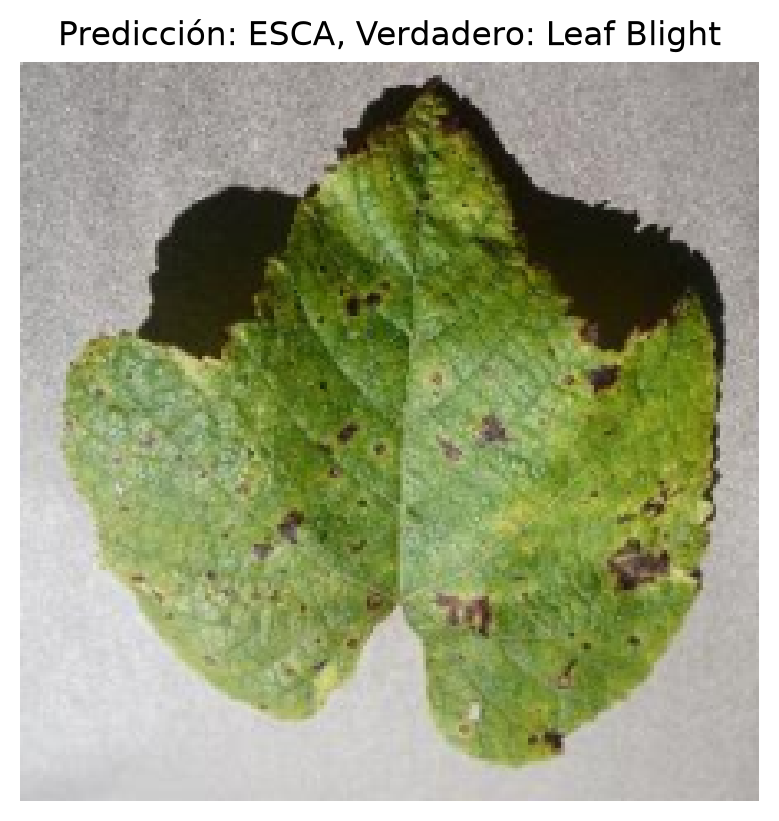

In [16]:
# Definir el dispositivo
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Obtener un lote de imágenes del dataset
dataiter = iter(trainloader) # Trae el Dataloader y lo convierte en un iterador
images, labels = next(dataiter) # Permite obtener el siguiente lote del iterador imagenes y labels

print(f"Tamaño del lote: {images.shape}")
print(f"Etiquetas: {labels[:10]}")
print()

# Hacer un pase hacia adelante con la primera imagen
images_device = images.to(device)  # Mueve todas las imagenes del lote al dispositivo GPU/CPU
output = model(images_device[0].unsqueeze(0)) # Obtiene la primer imagen del lote y la pasa por la red neuronal para obtener la prediccion, solo una para probar que funciona pero aun no esta entrenando

print("Salida de la red (probabilidades):")
print(output)
print()

# Obtener la predicción
pred = torch.argmax(output, dim=1)
print(f"Predicción: {pred.item()}")
print(f"Verdadero: {labels[0].item()}")
print(f"Clase predicha: {trainset.classes[pred.item()]}")
print(f"Clase verdadera: {trainset.classes[labels[0].item()]}")
print()

# Desnormalizar la imagen
img = images[0].numpy().transpose(1, 2, 0)
img = img * 0.5 + 0.5  # Deshace la normalización

plt.imshow(img)
plt.title(f"Predicción: {trainset.classes[pred.item()]}, Verdadero: {trainset.classes[labels[0].item()]}")
plt.axis('off')
plt.show()